**Linear SVM + T0: shared preprocessed baseline (73 features)**

This notebook loads the shared splits, build a sklearn pipeline, sweep six C values, inspect train/validation curves, select by validation
F1, analyze errors and save six rows to `results/svm_t0.csv`.

The inputs to LinearSVC have 73 columns, with 24,000 training rows and 6,000 validation rows. The official test split is not loaded or scored.

`preprocessing.ipynb` saves raw split CSVs. The model imports `load_split()` and `build_preprocessor()` from `src/preprocessing.py`

**Linear SVM: scores, margin and L2 regularization**

For the shared preprocessed row $z=T(x)\in\mathbb{R}^{73}$, a linear SVM uses

$$f(z)=w^\top z+b,\qquad \hat y=\mathbb{1}[f(z)>0].$$

A positive score predicts attack and a negative score predicts normal. An exact
zero score is assigned to class 0. The decision score is **not a probability**;
there is no sigmoid or 0.5 probability threshold here. The boundary $f(z)=0$ is
linear in the preprocessed space; shared log1p already changes some raw units.

Write the training labels as $t_i=2y_i-1\in\{-1,+1\}$. The signed functional
margin is $m_i=t_i f(z_i)$. The reference's squared-hinge loss is

$$\ell_i=\max(0,1-m_i)^2.$$

A correctly classified point with $m_i\ge1$ has zero loss; points inside the margin
or on the wrong side are penalized. With L2 regularization and no class/sample
weights, the usual objective is $\frac12\lVert w\rVert^2+C\sum_i\ell_i$.
For sklearn's liblinear-based `LinearSVC`, the fitted intercept is a synthetic
feature and is also penalized. More precisely, with `intercept_scaling=s`,

$$\min_{w,b}\;\frac12\left(\lVert w\rVert_2^2+\frac{b^2}{s^2}\right)
+C\sum_i\max(0,1-t_i(w^\top z_i+b))^2.$$

We use the default $s=1$, as in the reference. **Smaller C means stronger
regularization** relative to the loss; larger C penalizes margin violations more
strongly. Changing C alters the boundary coefficients, not the 73-feature space.
A unit functional margin is not a unit geometric distance: distance also depends
on $\lVert w\rVert$.

Sources: [sklearn LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html)
and [support-vector machines](https://scikit-learn.org/stable/modules/svm.html).

**1. Setup and shared splits**

The next block imports the same preprocessing and evaluator as T2. `load_split()`
returns raw model-input columns, binary labels and attack-type metadata. It drops
`id`, `label`, `attack_cat` and redundant `is_ftp_login` from predictors.

The output reports shapes, class counts and proportions. Checks verify 24,000/6,000
rows, a common 41-column raw schema, target alignment and no overlapping source
IDs. It reuses the existing split rather than resampling. Run
`preprocessing.ipynb` first if `data/processed/train.csv` and `val.csv` are absent.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "preprocessing.py").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.preprocessing import RANDOM_STATE, NOT_FEATURES, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = ROOT / "figures"
FIGS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
split_paths = [ROOT / "data" / "processed" / f"{name}.csv" for name in ("train", "val")]
if not all(path.is_file() for path in split_paths):
    raise FileNotFoundError("Run notebook/preprocessing.ipynb to generate the shared splits first.")
X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
assert X_train.shape == (24_000, 41) and X_val.shape == (6_000, 41)
assert X_train.columns.equals(X_val.columns)
assert X_train.index.equals(y_train.index) and X_val.index.equals(y_val.index)
assert not set(NOT_FEATURES).intersection(X_train.columns)
train_ids = pd.read_csv(split_paths[0], usecols=["id"])["id"]
val_ids = pd.read_csv(split_paths[1], usecols=["id"])["id"]
assert set(train_ids).isdisjoint(val_ids)
print("Raw inputs — train:", X_train.shape, "validation:", X_val.shape)
print("Row-ID overlap: 0. Official test split not loaded.")

balance = pd.DataFrame({
    "train_count": y_train.value_counts().reindex([0, 1], fill_value=0),
    "val_count": y_val.value_counts().reindex([0, 1], fill_value=0),
}).rename(index={0: "Normal", 1: "Attack"})
balance["train_share"] = balance["train_count"] / len(y_train)
balance["val_share"] = balance["val_count"] / len(y_val)
display(balance.round(4))

Raw inputs — train: (24000, 41) validation: (6000, 41)
Row-ID overlap: 0. Official test split not loaded.


,train_count,val_count,train_share,val_share
label,,,,
Normal,11559,2890,0.4816,0.4817
Attack,12441,3110,0.5184,0.5183


**2. Verify the T0 representation**

For T0 the additional map is the identity: Z is exactly the shared preprocessing
output. The next diagnostic block fits a separate preprocessor on training only
and uses `transform()` for validation. Each actual SVM will receive a fresh
preprocessor in its own pipeline.

The output confirms 73 finite features and their breakdown: **35 categorical
indicators + 31 log1p-scaled numeric + seven other scaled numeric**. The seven
include the retained TTL columns and a binary flag. Numeric scalers use training
statistics; categorical grouping and category lists are fixed by the shared EDA
plan. No extra scaler is added after shared preprocessing in T0, so the indicators
remain 0/1. This is the same baseline representation as LR T0.

In [2]:
preview_prep = build_preprocessor().fit(X_train)
Xt_train = preview_prep.transform(X_train)
Xt_val = preview_prep.transform(X_val)
feature_names = preview_prep.get_feature_names_out()
assert Xt_train.shape == (24_000, 73) and Xt_val.shape == (6_000, 73)
assert np.isfinite(Xt_train).all() and np.isfinite(Xt_val).all()
print("T0 model inputs — train:", Xt_train.shape, "validation:", Xt_val.shape)
print("No K-means, PCA, polynomial expansion or other additional feature mapping.")
display(pd.Series(feature_names).str.split("__").str[0].value_counts().rename("columns"))

T0 model inputs — train: (24000, 73) validation: (6000, 73)
No K-means, PCA, polynomial expansion or other additional feature mapping.


cat    35
log    31
num     7
Name: columns, dtype: int64

**How the dataset affects this baseline**

Heavy-tailed flow measurements motivate the existing log1p and scaling: without
appropriate scales, the units of a feature would affect the L2 penalty. One-hot
columns supply additive category effects. T0 cannot explicitly learn numeric
products, category-by-numeric interactions or distances to traffic clusters.

The EDA found correlated features, ambiguous feature vectors with conflicting
labels, and overlap between Fuzzers and Normal. A soft-margin model tolerates
violations instead of assuming perfect separation. We retain correlated inputs
and use L2 regularization; a small train/validation gap alone does not establish
underfitting. TTL-related lab shortcuts remain present and require a separate
removal experiment to assess generalization.

The roughly 52% attack prevalence and fixed stratified splits support comparison
with the reference's unweighted fit, so `class_weight=None` is retained. Report
precision, recall, F1 and FPR rather than accuracy alone. Deployment prevalence
can change precision even when recall and FPR stay similar. The earlier EDA saw
the full training file, so validation is held out from fitting, not from all exploration.

**3. Build the linear SVM pipeline**

`build(C, max_iter)` returns a fresh, unfitted pipeline:

**shared preprocessing (73 features) → LinearSVC**.

It uses the same `LinearSVC` family as T2, with explicit L2 penalty and squared-hinge
loss, `dual="auto"`, `random_state=42` and an initial 5,000-iteration limit. With
24,000 rows and 73 features, the supported auto choice uses primal optimization.
The intercept and its default scaling are retained. Each fit learns scalers and
SVM coefficients only from training, then reuses them for validation predictions.

Unlike T2, this pipeline has no K-means union and no final rescaling of appended
features. Thus T0/T2 comparisons reflect the full representation and scaling
choices, not an isolated causal effect of the cluster-distance columns alone.

In [3]:
def build(C, max_iter=5000):
    """Return an unfitted 73-feature T0 LinearSVC pipeline for one C setting."""
    return make_pipeline(
        build_preprocessor(),
        LinearSVC(C=C, penalty="l2", loss="squared_hinge", dual="auto",
                  max_iter=max_iter, random_state=RANDOM_STATE,
                  class_weight=None, fit_intercept=True, intercept_scaling=1.0),
    )

**4. Sweep six C values**

Use the same logarithmic grid as the SVM T2 reference:

| C | Decision rationale |
|---|---|
| 0.001 | Strong regularization: establish a constrained soft-margin baseline. |
| 0.01 | Reduce shrinkage tenfold to see whether useful signals were suppressed. |
| 0.1 | Intermediate regularization for a balance of fit and coefficient size. |
| 1 | Conventional default-C reference, also included in the other sweeps. |
| 10 | Weak regularization: check whether extra training fit improves validation. |
| 100 | Weakest regularization in this grid: inspect plateaus, gaps and convergence. |

`evaluate()` trains one pipeline and returns train/validation metrics, final fit
time and a convergence flag. It uses `predict()`, so all settings retain the zero
SVM decision threshold. `f1_gap` is training F1 minus validation F1.

Only a convergence warning triggers a retry at 10,000 then 20,000 iterations;
this does not use validation scores to change optimization. The CSV retains the
final attempt for every C and its convergence status. The separate diagnostic
table reports attempts, iterations, cumulative fit time and coefficient norm.
CSV `fit_time_s` is the final attempt's time. Fits run sequentially and are retained
for selection, avoiding an unnecessary refit of the winner.

In [4]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted, optimizer_rows = [], {}, []

for value in GRID:
    cumulative_fit_time = 0.0
    for attempt, budget in enumerate([5000, 10000, 20000], start=1):
        pipe = build(value, max_iter=budget)
        row = evaluate(pipe, "SVM", "T0", "C", value, X_train, y_train, X_val, y_val)
        cumulative_fit_time += row["fit_time_s"]
        if row["converged"]:
            break
        print(f"C={value:g}: no convergence at max_iter={budget}; "
              + ("retrying." if budget < 20000 else "retaining flagged result."), flush=True)
    classifier = pipe.named_steps["linearsvc"]
    assert classifier.n_features_in_ == 73
    assert len(pipe.steps) == 2
    prep = pipe.named_steps["columntransformer"]
    assert prep.named_transformers_["log"].named_steps["standardscaler"].n_samples_seen_ == len(X_train)
    assert prep.named_transformers_["num"].n_samples_seen_ == len(X_train)
    fitted[value] = pipe
    rows.append(row)
    optimizer_rows.append({
        "C": value, "attempts": attempt, "max_iter": budget,
        "iterations": int(np.max(classifier.n_iter_)),
        "cumulative_fit_time_s": round(cumulative_fit_time, 2),
        "coefficient_L2_norm": float(np.linalg.norm(classifier.coef_)),
    })
    print(f"C={value:g}: train F1={row['train_f1']:.4f}, val F1={row['val_f1']:.4f}, "
          f"fit time={row['fit_time_s']}s, converged={row['converged']}", flush=True)

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
optimizer_diagnostics = pd.DataFrame(optimizer_rows)
assert len(results) == 6 and results["value"].nunique() == 6
# Preserve the complete sweep before later analysis, including any flagged fits.
results.to_csv(RESULTS / "svm_t0.csv", index=False)
display(results.drop(columns=["model", "transformation", "param"]).round(4))
display(optimizer_diagnostics.round(4))

C=0.001: train F1=0.9115, val F1=0.9109, fit time=0.07s, converged=True


C=0.01: train F1=0.9141, val F1=0.9128, fit time=0.09s, converged=True


C=0.1: train F1=0.9158, val F1=0.9147, fit time=0.1s, converged=True


C=1: train F1=0.9161, val F1=0.9141, fit time=0.17s, converged=True


C=10: train F1=0.9167, val F1=0.9138, fit time=0.37s, converged=True


C=100: train F1=0.9168, val F1=0.9140, fit time=0.39s, converged=True


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8587,0.9712,0.9115,0.1721,0.8611,0.9669,0.9109,0.1678,0.07,True,0.0005
1,0.010,0.8646,0.9697,0.9141,0.1634,0.8665,0.9643,0.9128,0.1599,0.09,True,0.0013
2,0.100,0.8719,0.9645,0.9158,0.1525,0.8734,0.9601,0.9147,0.1498,0.10,True,0.0012
3,1.000,0.8748,0.9617,0.9161,0.1482,0.8750,0.9569,0.9141,0.1471,0.17,True,0.0020
4,10.000,0.8758,0.9617,0.9167,0.1468,0.8750,0.9563,0.9138,0.1471,0.37,True,0.0029
5,100.000,0.8761,0.9614,0.9168,0.1463,0.8752,0.9563,0.9140,0.1467,0.39,True,0.0028


,C,attempts,max_iter,iterations,cumulative_fit_time_s,coefficient_L2_norm
0,0.001,1,5000,6,0.07,1.0974
1,0.010,1,5000,7,0.09,2.0648
2,0.100,1,5000,8,0.10,3.5258
3,1.000,1,5000,11,0.17,5.5767
4,10.000,1,5000,22,0.37,8.2027
5,100.000,1,5000,21,0.39,9.4156


**5. Validation curves**

The same `plot_sweep()` used by SVM T2 plots training F1 (dashed) and validation
F1 (solid) on the left, and validation precision, recall and FPR on the right.
The horizontal axis is logarithmic C: moving right weakens regularization.

A rising training score with worsening validation and a widening positive gap is
consistent with overfitting. A plateau can indicate that changing C is no longer
addressing the remaining errors; it does not prove a specific cause. The right
plot shows whether lower false-alarm rates are bought at the cost of missed
attacks. The generated caption describes this run, not the T2 template's results.

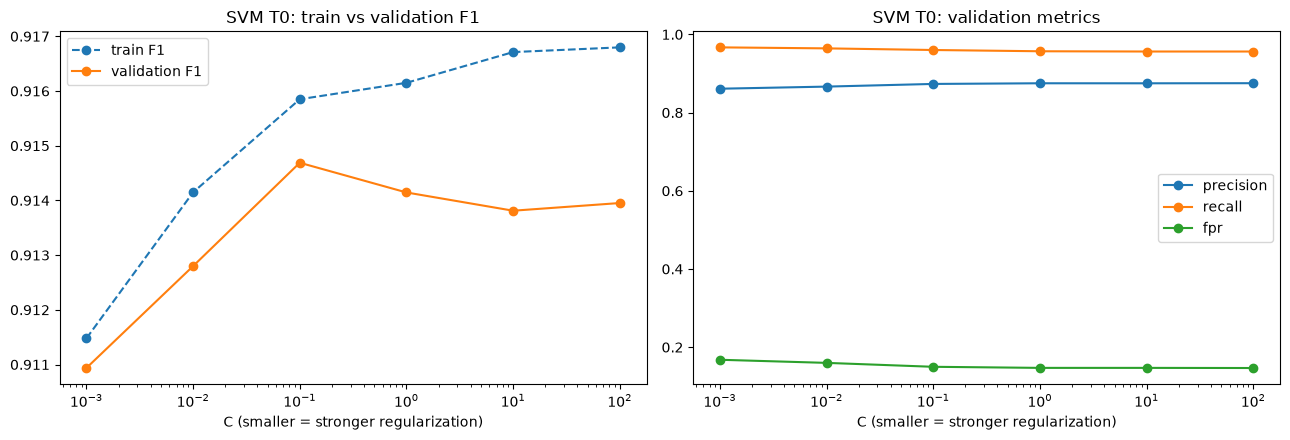

**Observed sweep:** from C=0.001 to C=100, training F1 changes from 0.9115 to 0.9168, and validation F1 from 0.9109 to 0.9140. The train-minus-validation F1 gap ranges from +0.0005 to +0.0029. FPR changes from 16.78% to 14.67%, while attack recall changes from 96.69% to 95.63%. These are descriptive results on one split, not significance tests. A small gap does not establish that additional nonlinear features will help.

In [5]:
plot_sweep(results, "SVM T0", FIGS / "curve_svm_t0.png")
a, b = results.iloc[0], results.iloc[-1]
display(Markdown(
    f"**Observed sweep:** from C={a['value']:g} to C={b['value']:g}, training F1 "
    f"changes from {a['train_f1']:.4f} to {b['train_f1']:.4f}, and validation F1 "
    f"from {a['val_f1']:.4f} to {b['val_f1']:.4f}. The train-minus-validation F1 "
    f"gap ranges from {results['f1_gap'].min():+.4f} to {results['f1_gap'].max():+.4f}. "
    f"FPR changes from {a['val_fpr']:.2%} to {b['val_fpr']:.2%}, while attack recall "
    f"changes from {a['val_recall']:.2%} to {b['val_recall']:.2%}. "
    "These are descriptive results on one split, not significance tests. "
    "A small gap does not establish that additional nonlinear features will help."
))

**Interpretation of the recorded run.** Validation F1 peaks at **C=0.1 (0.9147)**. With weaker regularization, training F1 continues to increase slightly but validation stays below that peak. The largest F1 gap is only 0.0029; this offers little evidence of severe overfitting on this split, and does not prove that the model is underfitting. All six settings converged within the initial 5,000-iteration budget.

The right graph shows that increasing C reduces false alarms but also loses some attack recall. Selecting by F1 therefore differs from selecting the lowest FPR or highest recall. The winner lies within the tested range, so this sweep already brackets a useful C region. The small score differences require caution on a single validation split. Refresh this paragraph if the data or settings change.

**6. Select the best converged setting**

Select the highest validation F1 among converged runs, matching the reference's
selection metric. Exact ties use the first row of the ascending grid, favoring
stronger regularization. Flagged unconverged runs remain in the CSV but are not
eligible. An edge winner merits considering a broader grid in a later experiment.

The output reports the chosen C, precision, recall and FPR, and verifies a small
validation transformation still has exactly 73 columns. No validation `fit()` is
performed. Because validation selects C, this score is not an untouched test
estimate. Tiny differences between C values should not be overinterpreted.

In [6]:
eligible = results[results["converged"]]
if eligible.empty:
    raise RuntimeError("No converged fit; the six-row CSV is saved. Review optimization before selection.")
best = eligible.loc[eligible["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"Best C={best['value']:g}: val F1={best['val_f1']:.4f}, "
      f"precision={best['val_precision']:.4f}, recall={best['val_recall']:.4f}, "
      f"FPR={best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("Best C is at the edge: consider a wider grid in a follow-up experiment.")
Z_check = best_model[:-1].transform(X_val.iloc[:4])
assert Z_check.shape == (4, 73) and np.isfinite(Z_check).all()
print("Verified classifier input dimensions: train (24000, 73), validation (6000, 73).")

Best C=0.1: val F1=0.9147, precision=0.8734, recall=0.9601, FPR=0.1498
Verified classifier input dimensions: train (24000, 73), validation (6000, 73).


**Validation confusion matrix**

The graph's rows are true labels and columns are predicted labels. Top-right is
false alarms (FP), bottom-left is missed attacks (FN). This makes the operational
trade-off visible alongside the shared evaluator's metrics:

$$\mathrm{Precision}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2TP}{2TP+FP+FN},\quad
\mathrm{FPR}=\frac{FP}{FP+TN}.$$

The output caption gives counts and the correct denominators. FPR concerns normal
traffic: projected false alarms equal FPR times the number of normal flows.

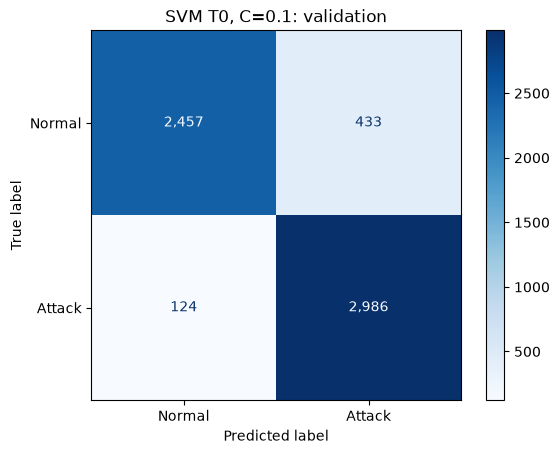

The selected model makes **433 false alarms** among 2,890 normal flows (FPR 14.98%) and misses **124 attacks** among 3,110 attacks (3.99%). The linear boundary may still confuse overlapping or inconsistently labelled feature vectors; these counts alone do not identify each error's cause.

In [7]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",",
)
plt.title(f"SVM T0, C={best['value']:g}: validation")
plt.savefig(FIGS / "confusion_svm_t0.png", dpi=150, bbox_inches="tight")
plt.show()
tn, fp, fn, tp = confusion_matrix(y_val, pred_val, labels=[0, 1]).ravel()
display(Markdown(
    f"The selected model makes **{fp:,} false alarms** among {tn + fp:,} normal "
    f"flows (FPR {fp / (tn + fp):.2%}) and misses **{fn:,} attacks** among "
    f"{tp + fn:,} attacks ({fn / (tp + fn):.2%}). "
    "The linear boundary may still confuse overlapping or inconsistently labelled "
    "feature vectors; these counts alone do not identify each error's cause."
))

**Signed margins: connect SVM loss to the validation errors**

`decision_function()` returns signed scores, not probabilities. Multiplying by
+1 for attack and -1 for normal gives the signed functional margin. The next
histogram plots validation margins, colored by true class; it is diagnostic and
is not used to choose C or a new threshold.

The vertical line at zero separates wrong-side points from correct-side points;
the line at one marks where squared-hinge loss becomes zero. Points between zero
and one are correctly classified but still penalized. The plotting range uses
validation quantiles only to make the graph readable; the printed counts and
loss include **all** validation rows, including those outside the visible range.
LinearSVC does not expose `support_vectors_`; margin violations are not reported
as a count of sklearn support vectors.

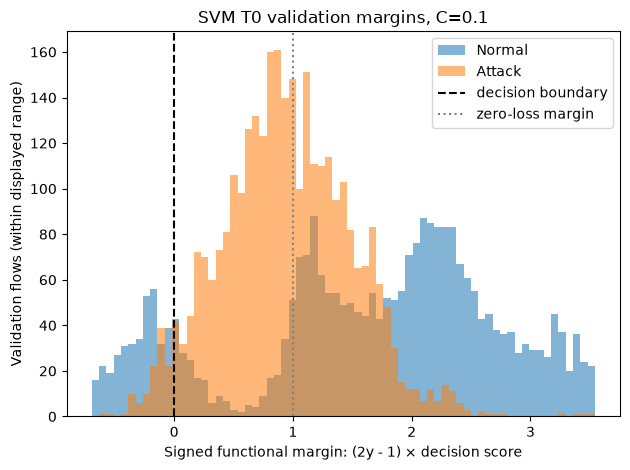

rows                            6000.000000
wrong_side_margin_below_zero     557.000000
exact_zero_margin                  0.000000
positive_margin_below_one       1875.000000
margin_at_least_one             3568.000000
mean_squared_hinge_loss            0.249666
dtype: float64

In [8]:
val_scores = best_model.decision_function(X_val)
signed_margins = (2 * y_val.to_numpy() - 1) * val_scores
assert np.isfinite(signed_margins).all()
lo, hi = np.quantile(signed_margins, [0.01, 0.99])
lo, hi = min(float(lo), -0.1), max(float(hi), 1.1)
bins = np.linspace(lo, hi, 70)
for label, name in [(0, "Normal"), (1, "Attack")]:
    plt.hist(signed_margins[y_val.to_numpy() == label], bins=bins, alpha=0.55, label=name)
plt.axvline(0, color="black", linestyle="--", label="decision boundary")
plt.axvline(1, color="gray", linestyle=":", label="zero-loss margin")
plt.xlabel("Signed functional margin: (2y - 1) × decision score")
plt.ylabel("Validation flows (within displayed range)")
plt.title(f"SVM T0 validation margins, C={best['value']:g}")
plt.legend()
plt.tight_layout()
plt.savefig(FIGS / "margins_svm_t0.png", dpi=150, bbox_inches="tight")
plt.show()
margin_summary = pd.Series({
    "rows": len(signed_margins),
    "wrong_side_margin_below_zero": int((signed_margins < 0).sum()),
    "exact_zero_margin": int((signed_margins == 0).sum()),
    "positive_margin_below_one": int(((signed_margins > 0) & (signed_margins < 1)).sum()),
    "margin_at_least_one": int((signed_margins >= 1).sum()),
    "mean_squared_hinge_loss": float(np.maximum(0, 1 - signed_margins).dot(np.maximum(0, 1 - signed_margins)) / len(signed_margins)),
})
display(margin_summary)

**Interpretation of the recorded margin graph.** There are **557 negative signed margins**, matching 433 false alarms plus 124 missed attacks; no score is exactly zero in this run. Another **1,875** examples are correctly classified but have positive margin below one, so squared-hinge loss still penalizes them. The remaining **3,568** have margin at least one and contribute zero hinge loss. This distinction explains why SVM optimization depends on more than the count of classification errors. The average validation squared-hinge loss is about **0.2497**. The visible histogram omits the extreme margins for readability, whereas these counts include all 6,000 validation rows. Refresh this paragraph if the data or selected model changes.

**Which attack types are missed?**

`attack_recall()` uses `attack_cat` only as validation metadata and returns rows,
caught/missed counts and recall by attack type, sorted by recall. This shows
whether a good overall F1 hides a weak attack category. Compare absolute misses
as well as rates, especially for the common Fuzzers type highlighted in the EDA.
Small groups such as Worms have uncertain recall estimates even at 100%.

In [9]:
by_attack = attack_recall(y_val, pred_val, cat_val)
display(by_attack)
most_missed = by_attack["missed"].idxmax()
display(Markdown(
    f"**{most_missed}** contributes the most missed attacks: "
    f"{int(by_attack.loc[most_missed, 'missed'])} of {int(by_attack['missed'].sum())}. "
    "Use this table to motivate later experiments, without treating validation "
    "error analysis as a final test result."
))

,rows,caught,missed,recall
type,,,,
Fuzzers,899,801,98,0.891
Analysis,89,86,3,0.966
DoS,212,206,6,0.972
Backdoor,85,83,2,0.976
Exploits,1105,1094,11,0.990
Generic,233,231,2,0.991
Reconnaissance,419,417,2,0.995
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


**Fuzzers** contributes the most missed attacks: 98 of 124. Use this table to motivate later experiments, without treating validation error analysis as a final test result.

**Coefficient inspection on named baseline features**

The following table lists the 15 largest absolute SVM coefficients and their
feature names. A positive coefficient increases the attack decision score; a
negative one decreases it, holding other encoded values fixed. Numeric coefficients
refer to one training standard deviation after any log1p; categorical indicators
remain 0/1. Absolute weights across these groups are therefore not a universal
importance ranking. Correlated columns share weights and coefficients are not
causal evidence. Retained TTL associations should be investigated by a separate
refit without those columns.

In [10]:
names = best_model.named_steps["columntransformer"].get_feature_names_out()
weights = best_model.named_steps["linearsvc"].coef_[0]
assert len(names) == len(weights) == 73
coefficient_table = pd.DataFrame({"feature": names, "coefficient": weights})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
display(coefficient_table.nlargest(15, "absolute_coefficient").round(4))

,feature,coefficient,absolute_coefficient
31,cat__state_CON,-1.3966,1.3966
67,num__dttl,1.2992,1.2992
30,cat__state_INT,1.0294,1.0294
39,log__dbytes,0.9506,0.9506
42,log__dload,-0.9297,0.9297
53,log__dmean,0.9102,0.9102
19,cat__service_smtp,0.7876,0.7876
33,cat__state_RST,0.7638,0.7638
1,cat__proto_udp,-0.6562,0.6562
68,num__swin,-0.6539,0.6539


**Compare with the recorded SVM T2/T3 results**

For context, the next block selects each existing SVM CSV's best converged
validation F1 and compares it with this T0 run. It does not retrain or modify the
reference results. Missing CSVs are skipped. Comparisons assume the same shared
splits and may involve different software or timing conditions; small differences
on one validation split do not establish significance.

T2 uses original features plus cluster distances followed by another scaler;
T3 uses PCA and polynomial features. Their extra scaling and representation are
part of the comparison. The current T0 baseline is unchanged by this table.

In [11]:
comparison_rows = []
for label, filename in [
    ("T0: shared baseline (73)", "svm_t0.csv"),
    ("T2: appended K-means distances (93)", "svm_t2_kmeans.csv"),
    ("T3: PCA(20) + polynomial degree 2 (230)", "svm_t3_pca_poly2.csv"),
]:
    path = RESULTS / filename
    if not path.is_file():
        print("Reference unavailable:", filename)
        continue
    recorded = results if filename == "svm_t0.csv" else pd.read_csv(path)
    candidates = recorded[recorded["converged"]]
    if candidates.empty:
        continue
    winner = candidates.loc[candidates["val_f1"].idxmax()]
    comparison_rows.append({"representation": label, "best_C": winner["value"],
                            **{metric: winner[metric] for metric in
                               ["val_precision", "val_recall", "val_f1", "val_fpr"]}})
display(pd.DataFrame(comparison_rows).round(4))

,representation,best_C,val_precision,val_recall,val_f1,val_fpr
0,T0: shared baseline (73),0.1,0.8734,0.9601,0.9147,0.1498
1,T2: appended K-means distances (93),1.0,0.8830,0.9534,0.9168,0.1360
2,T3: PCA(20) + polynomial degree 2 (230),1.0,0.8909,0.9457,0.9175,0.1246


**7. Save and verify the results CSV**

Save `results/svm_t0.csv` with `model="SVM"`, `transformation="T0"` and `param="C"`.
It contains every C, not just the winner, using the shared evaluator's columns
plus `f1_gap`, matching the reference schema. The reload checks six unique C
values, finite metrics in [0,1], correct labels and unchanged F1 values.

Three T0-specific figure files preserve the validation curve, confusion matrix
and margin histogram. The fitted pipelines stay in `fitted` for this notebook
session; models and transformed datasets are not serialized. Cross-validation,
if added later, should fit the complete pipeline on raw training inputs inside
each fold. The official test remains for final evaluation after model selection.

In [12]:
output_path = RESULTS / "svm_t0.csv"
results.to_csv(output_path, index=False)
reloaded = pd.read_csv(output_path)
assert len(reloaded) == 6 and reloaded["value"].tolist() == GRID
assert set(reloaded["model"]) == {"SVM"} and set(reloaded["transformation"]) == {"T0"}
assert set(reloaded["param"]) == {"C"}
metric_columns = [name for name in reloaded if name.startswith(("train_", "val_"))]
assert np.isfinite(reloaded[metric_columns].to_numpy()).all()
assert reloaded[metric_columns].apply(lambda column: column.between(0, 1).all()).all()
assert np.allclose(reloaded["val_f1"], results["val_f1"], rtol=0, atol=1e-12)
reference_csv = RESULTS / "svm_t2_kmeans.csv"
if reference_csv.is_file():
    assert reloaded.columns.tolist() == pd.read_csv(reference_csv, nrows=0).columns.tolist()
print("Saved and verified", len(reloaded), "rows:", output_path)
print("Converged settings:", int(reloaded["converged"].sum()), "of 6")
print("Plots:", ", ".join(str(FIGS / name) for name in
      ["curve_svm_t0.png", "confusion_svm_t0.png", "margins_svm_t0.png"]))

Saved and verified 6 rows: /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/results/svm_t0.csv
Converged settings: 6 of 6
Plots: /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/figures/curve_svm_t0.png, /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/figures/confusion_svm_t0.png, /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/figures/margins_svm_t0.png
